# Solving the n-Queens Problem using Local Search

Student Name: Đào Duy Hưng  
Student ID: 3122410158

I have used the following AI tools: ChatGPT (OpenAI) to assist with the Bài 5 modeling explanation, additional verification, and presentation. Review and understand all submitted work.

I understand that my submission needs to be my own work: [your initials – điền trước khi nộp]


## Learning Outcomes

* Implement multiple hill climbing search variants to solve the n-Queens problem.
* Apply simulated annealing with appropriate temperature scheduling to overcome local optima.
* Compare algorithm performance using runtime, solution quality, and success rate metrics.
* Analyze and visualize algorithm performance across different problem sizes.
* Graduate Students: Design and test alternative local move operators to improve search efficiency.

## Instructions

Total Points: Undergrads 100 + 5 bonus / Graduate students 110

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook as a HTML file. 

In [1]:
# Tùy chọn cho Google Colab: không tự động thay đổi thư mục làm việc.
# Nếu cần lưu lên Drive, tự mount rồi chọn thư mục trong phiên chạy của bạn.
# from google.colab import drive
# drive.mount('/content/drive')
# (Không sử dụng os.chdir() với đường dẫn cá nhân.)


## The n-Queens Problem

* __Goal:__ Find an arrangement of $n$ queens on a $n \times n$ chess board so that no queen is on the same row, column or diagonal as any other queen.

* __State space:__ An arrangement of the queens on the board. We restrict the state space to arrangements where there is only a single queen per column. We represent a state as an integer vector $\mathbf{q} = \{q_1, q_2, \dots, q_n\}$, each number representing the row positions of the queens from left to right. We will call a state a "board."

* __Objective function:__ The number of pairwise conflicts (i.e., two queens in the same row/column/diagonal).
The optimization problem is to find the optimal arrangement $\mathbf{q}^*$ of $n$ queens on the board can be written as:

  > minimize: $\mathrm{conflicts}(\mathbf{q})$
  >
  > subject to: $\mathbf{q} \ \text{contains only one queen per column}$

  Note: the constraint (subject to) is enforced by the definition of the state space.

* __Local improvement move:__ Move one queen to a different row in its column.

* __Termination:__ For this problem there is always an arrangement $\mathbf{q}^*$ with $\mathrm{conflicts}(\mathbf{q}^*) = 0$, however, the local improvement moves might end up in a local minimum. 

## Helper functions

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors

np.random.seed(1234)


def random_board(n):
    """Creates a random board of size n x n. Note that only a single queen is placed in each column!"""
    
    return(np.random.randint(0,n, size = n))

def comb2(n): return n*(n-1)//2 # this is n choose 2 equivalent to math.comb(n, 2); // is int division

def conflicts(board):
    """Calculate the number of conflicts, i.e., the objective function."""

    n = len(board)
    
    horizontal_cnt = [0] * n
    diagonal1_cnt = [0] * 2 * n
    diagonal2_cnt = [0] * 2 * n
    
    for i in range(n):
        horizontal_cnt[board[i]] += 1
        diagonal1_cnt[i + board[i]] += 1
        diagonal2_cnt[i - board[i] + n] += 1
    
    return sum(map(comb2, horizontal_cnt + diagonal1_cnt + diagonal2_cnt))

# decrease the font size to fit larger boards
def show_board(board, cols = ['white', 'gray'], fontsize = 48):  
    """display the board"""
    
    n = len(board)
    
    # create chess board display
    display = np.zeros([n,n])
    for i in range(n):
        for j in range(n):
            if (((i+j) % 2) != 0): 
                display[i,j] = 1
    
    cmap = colors.ListedColormap(cols)
    fig, ax = plt.subplots()
    ax.imshow(display, cmap = cmap, 
              norm = colors.BoundaryNorm(range(len(cols)+1), cmap.N))
    ax.set_xticks([])
    ax.set_yticks([])
    
    # place queens. Note: Unicode u265B is a black queen
    for j in range(n):
        plt.text(j, board[j], u"\u265B", fontsize = fontsize, 
                 horizontalalignment = 'center',
                 verticalalignment = 'center')
    
    print(f"Board with {conflicts(board)} conflicts.")
    plt.show()

## Create a board

Board with 4 conflicts.


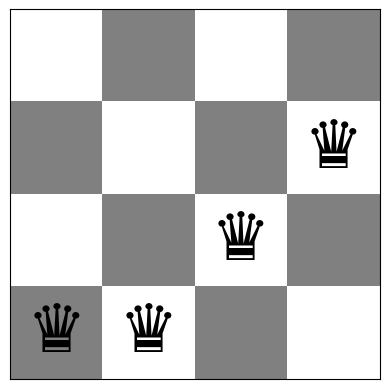

Queens (left to right) are at rows: [3 3 2 1]
Number of conflicts: 4


In [3]:
board = random_board(4)

show_board(board)
print(f"Queens (left to right) are at rows: {board}")
print(f"Number of conflicts: {conflicts(board)}")

A board $4 \times 4$ with no conflicts:

Board with 0 conflicts.


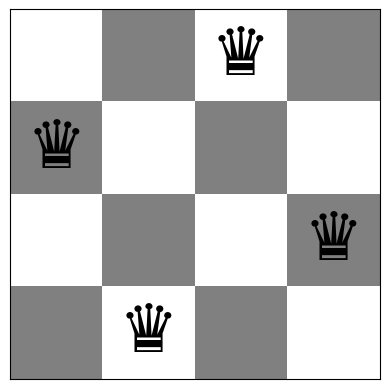

In [4]:
board = [1,3,0,2]
show_board(board)

# LAB04 – Bài 5. Biểu diễn bài toán n quân hậu (n-Queens)

### 5.1. Mục tiêu và mô hình hóa trạng thái

Bài thực hành sử dụng trực tiếp ba hàm gốc `random_board(n)`, `show_board(board)` và `conflicts(board)` trong notebook. Trong cách biểu diễn đang dùng, `board` là một vector $n$ phần tử:

$$board=[q_0,q_1,\dots,q_{n-1}],\qquad q_i\in\{0,1,\dots,n-1\}.$$

- Chỉ số `i` là **cột**; `board[i]` là **hàng** đặt quân hậu tại cột đó (chỉ số bắt đầu từ 0).
- Mỗi cột có đúng một quân hậu do mỗi cột ứng với đúng một phần tử của vector.
- Hai quân hậu tại cột $i$ và $j$ ($i<j$) xung đột khi $q_i=q_j$ (cùng hàng), hoặc $|q_i-q_j|=|i-j|$ (cùng đường chéo). Hai quân ở hai cột khác nhau nên không xảy ra xung đột cùng cột.
- Hàm mục tiêu là $h(board)=\mathrm{conflicts}(board)$, tức **số cặp quân hậu tấn công nhau**. Bài toán cần tối thiểu hóa $h$; nghiệm hợp lệ khi và chỉ khi $h(board)=0$.

Với $n$ cột và $n$ lựa chọn hàng cho mỗi cột, không gian biểu diễn có $n^n$ trạng thái. Chú ý đây là số cấu hình theo quy tắc một hậu/cột, **không** phải số nghiệm hợp lệ.

### 5.2. Cách hàm `conflicts()` tính số xung đột

Notebook sử dụng ba dãy đếm: số hậu theo **hàng** `q[i]`, theo đường chéo `i+q[i]`, và theo đường chéo `i-q[i]+n`. Mỗi nhóm chứa $k$ quân hậu sẽ đóng góp $\binom{k}{2}=k(k-1)/2$ cặp xung đột. Vì vậy:

$$h(board)=\sum_{r=0}^{n-1}\binom{R_r}{2}+\sum_{d}\binom{D_d^{(+)}}{2}+\sum_{d}\binom{D_d^{(-)}}{2}.$$

Phương pháp đếm theo nhóm này được đối chiếu bên dưới với hàm kiểm tra độc lập từng cặp quân hậu; hai cách phải luôn cho cùng kết quả.

In [5]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# Sử dụng cùng seed và thứ tự sinh để có thể chạy lại và nhận đúng kết quả.
BAI5_SEED = 20261020
np.random.seed(BAI5_SEED)
board_4 = random_board(4)
board_8 = random_board(8)
reference_4 = np.array([1, 3, 0, 2], dtype=int)
reference_8 = np.array([0, 4, 7, 5, 2, 6, 1, 3], dtype=int)

RESULT_DIR_B5 = Path('Lab04_Bai5_Results')
RESULT_DIR_B5.mkdir(exist_ok=True)

board_cases = [
    ('4-Queens ngẫu nhiên', np.asarray(board_4, dtype=int)),
    ('4-Queens mẫu [1,3,0,2]', reference_4),
    ('8-Queens ngẫu nhiên', np.asarray(board_8, dtype=int)),
    ('8-Queens đối chứng hợp lệ', reference_8),
]

rows = []
for name, b in board_cases:
    rows.append({
        'case': name, 'n': len(b), 'board': str(b.tolist()),
        'h_conflicts': int(conflicts(b)),
        'has_solution': bool(conflicts(b) == 0),
        'state_space_size': int(len(b) ** len(b)),
    })
boards_df = pd.DataFrame(rows)
boards_df.to_csv(RESULT_DIR_B5 / 'Bai5_Queens_Boards.csv', index=False, encoding='utf-8-sig')
print(f'Seed: {BAI5_SEED}. Bảng kết quả 4-Queens và 8-Queens:')
display(boards_df)


Seed: 20261020. Bảng kết quả 4-Queens và 8-Queens:


,case,n,board,h_conflicts,has_solution,state_space_size
0,4-Queens ngẫu nhiên,4,"[0, 0, 3, 0]",3,False,256
1,"4-Queens mẫu [1,3,0,2]",4,"[1, 3, 0, 2]",0,True,256
2,8-Queens ngẫu nhiên,8,"[6, 2, 3, 7, 4, 1, 6, 4]",5,False,16777216
3,8-Queens đối chứng hợp lệ,8,"[0, 4, 7, 5, 2, 6, 1, 3]",0,True,16777216


### 5.3. Kiểm chứng $h(board)=0$ và điều kiện không có cặp hậu xung đột

Viết một bộ kiểm tra tham chiếu khác cách cài đặt gốc: duyệt từng cặp cột $(i,j)$, $i<j$, và ghi nhận cặp xung đột theo hàng hoặc đường chéo. Với một bàn cờ có dữ liệu hợp lệ, số cặp trả về phải **bằng** `conflicts(board)`.

Ta kiểm tra toàn bộ $4^4=256$ vector của 4-Queens và thêm các bàn cờ 8-Queens sinh ngẫu nhiên với seed riêng. Kiểm tra đầy đủ 4-Queens là phép duyệt vét cạn để xác nhận tính đúng đắn trên mọi trạng thái của kích thước đó. Kiểm tra 8-Queens chỉ bao gồm tập mẫu, **không** phải chứng minh bằng thực nghiệm cho toàn bộ $8^8$ vector.

In [6]:
from itertools import product

def attack_pairs(board):
    """Liệt kê các cặp (i, j) cùng hàng hoặc cùng đường chéo, i < j."""
    b = np.asarray(board, dtype=int)
    n = len(b)
    if n < 1 or np.any(b < 0) or np.any(b >= n):
        raise ValueError('board phải là vector hợp lệ: 0 <= board[i] < n')
    pairs = []
    for i in range(n):
        for j in range(i + 1, n):
            if b[i] == b[j] or abs(int(b[i])-int(b[j])) == j-i:
                pairs.append((i, j))
    return pairs

# Toàn bộ trạng thái của n=4; ngoài ra thử 500 cấu hình độc lập ở n=8.
rng_validation = np.random.default_rng(BAI5_SEED + 1)
all_4 = [np.asarray(b, dtype=int) for b in product(range(4), repeat=4)]
sampled_8 = [rng_validation.integers(0, 8, size=8) for _ in range(500)]
check_cases = [('4-Queens toàn bộ', all_4), ('8-Queens lấy mẫu', sampled_8)]
validation_rows = []
for description, collection in check_cases:
    mismatch = sum(int(conflicts(b) != len(attack_pairs(b))) for b in collection)
    zero_mismatch = sum(int((conflicts(b)==0) != (len(attack_pairs(b))==0)) for b in collection)
    validation_rows.append({'test': description, 'tested_boards': len(collection),
                            'count_mismatches': mismatch, 'zero_equivalence_mismatches': zero_mismatch,
                            'status': 'PASS' if mismatch==0 and zero_mismatch==0 else 'FAIL'})
    assert mismatch == 0 and zero_mismatch == 0, f'Lỗi bộ kiểm tra: {description}'

for name, b in board_cases:
    assert conflicts(b) == len(attack_pairs(b)), name
assert conflicts(reference_4) == 0
assert conflicts(reference_8) == 0

validation_df = pd.DataFrame(validation_rows)
validation_df.to_csv(RESULT_DIR_B5 / 'Bai5_Queens_Validation.csv', index=False, encoding='utf-8-sig')
display(validation_df)
print('Các cặp xung đột của từng bàn cờ minh họa:')
pair_rows=[]
for name,b in board_cases:
    pair_rows.append({'case':name, 'n':len(b), 'h_conflicts': int(conflicts(b)),
                      'attacking_column_pairs':str(attack_pairs(b))})
pairs_df = pd.DataFrame(pair_rows)
pairs_df.to_csv(RESULT_DIR_B5 / 'Bai5_Queens_Conflict_Pairs.csv', index=False, encoding='utf-8-sig')
display(pairs_df)


,test,tested_boards,count_mismatches,zero_equivalence_mismatches,status
0,4-Queens toàn bộ,256,0,0,PASS
1,8-Queens lấy mẫu,500,0,0,PASS


Các cặp xung đột của từng bàn cờ minh họa:


,case,n,h_conflicts,attacking_column_pairs
0,4-Queens ngẫu nhiên,4,3,"[(0, 1), (0, 3), (1, 3)]"
1,"4-Queens mẫu [1,3,0,2]",4,0,[]
2,8-Queens ngẫu nhiên,8,5,"[(0, 5), (0, 6), (1, 2), (4, 6), (4, 7)]"
3,8-Queens đối chứng hợp lệ,8,0,[]


### 5.4. Trực quan hóa các bàn cờ bằng `show_board()`

Dưới đây là các hình từ **hàm gốc của giảng viên**: hai cấu hình ngẫu nhiên tương ứng $n=4$ và $n=8$, cấu hình mẫu `[1,3,0,2]`, và một nghiệm 8-Queens dùng để đối chiếu. Các hình lưu riêng phía dưới được vẽ lại theo cùng tọa độ `board[i]` để có tệp PNG có thể nộp cùng notebook.

4-Queens ngẫu nhiên:
Board with 3 conflicts.


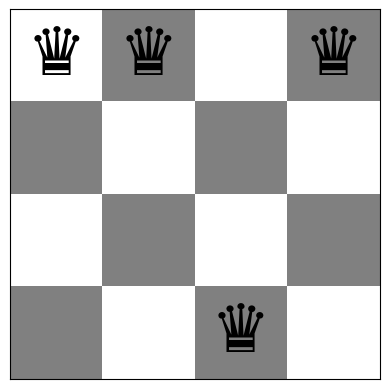

4-Queens mẫu [1, 3, 0, 2]:
Board with 0 conflicts.


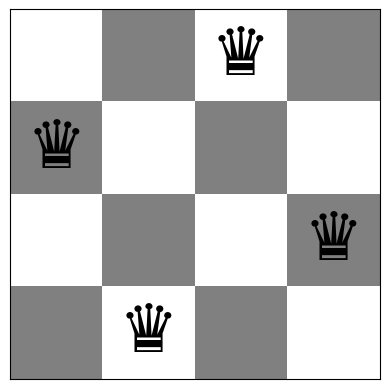

8-Queens ngẫu nhiên:
Board with 5 conflicts.


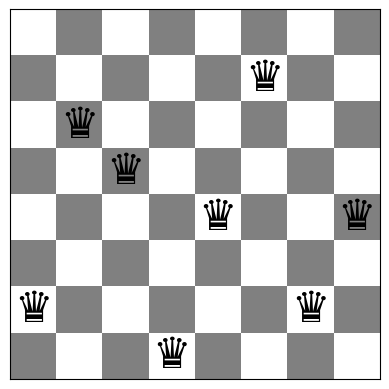

8-Queens nghiệm tham chiếu:
Board with 0 conflicts.


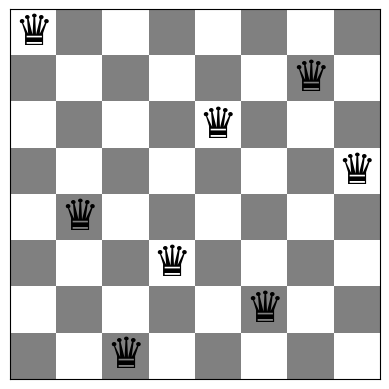

In [7]:
# Dùng trực tiếp show_board() như yêu cầu của Bài 5.
print('4-Queens ngẫu nhiên:')
show_board(board_4, fontsize=48)
print('4-Queens mẫu [1, 3, 0, 2]:')
show_board(reference_4, fontsize=48)
print('8-Queens ngẫu nhiên:')
show_board(board_8, fontsize=31)
print('8-Queens nghiệm tham chiếu:')
show_board(reference_8, fontsize=31)


In [8]:
# Xuất PNG từ dữ liệu đã kiểm chứng (không thay đổi hàm show_board() gốc).
from matplotlib.colors import ListedColormap

def draw_board_png(board, name, filename):
    b = np.asarray(board, dtype=int)
    n = len(b)
    squares = np.fromfunction(lambda r,c:(r+c)%2, (n,n))
    fig, ax = plt.subplots(figsize=(5.1,5.1))
    ax.imshow(squares, cmap=ListedColormap(['#f7f7f7','#909090']), vmin=0, vmax=1)
    for c, r in enumerate(b):
        ax.text(c, int(r), '♛', ha='center', va='center', color='black',
                fontsize=33 if n==4 else 23)
    ax.set_xticks(range(n))
    ax.set_yticks(range(n))
    ax.set_xlabel('Cột (i)'); ax.set_ylabel('Hàng (board[i])')
    ax.set_title(f'{name} | h(board) = {int(conflicts(b))}', fontsize=11)
    ax.set_xticks(np.arange(-.5, n, 1), minor=True)
    ax.set_yticks(np.arange(-.5, n, 1), minor=True)
    ax.grid(which='minor', color='black', linewidth=.55)
    ax.tick_params(which='minor', bottom=False, left=False)
    ax.set_xlim(-.5,n-.5); ax.set_ylim(n-.5,-.5)
    fig.tight_layout()
    fig.savefig(RESULT_DIR_B5 / filename, dpi=160)
    plt.close(fig)

for name,b in board_cases:
    n=len(b)
    filename = {
        '4-Queens ngẫu nhiên':'Bai5_4Queens_Random.png',
        '4-Queens mẫu [1,3,0,2]':'Bai5_4Queens_Reference.png',
        '8-Queens ngẫu nhiên':'Bai5_8Queens_Random.png',
        '8-Queens đối chứng hợp lệ':'Bai5_8Queens_Reference.png',
    }[name]
    draw_board_png(b, name, filename)
print('Đã xuất bốn hình PNG vào:', RESULT_DIR_B5)


Đã xuất bốn hình PNG vào: Lab04_Bai5_Results


### 5.5. Nhận xét kết quả và kết luận Bài 5

- Hai cấu hình được tạo bằng `random_board(n)` luôn có một quân hậu trên **mỗi cột**, nhưng vẫn có thể xung đột theo hàng và đường chéo. Điều này giải thích vì sao khởi tạo ngẫu nhiên chưa bảo đảm là nghiệm.
- Cấu hình mẫu `[1,3,0,2]` cho giá trị $h(board)=0$, vì không tồn tại cặp hậu cùng hàng hay cùng đường chéo. Cấu hình 8-Queens đối chứng cũng có $h=0$.
- Kết quả của `conflicts(board)` trùng với phép kiểm tra độc lập từng cặp hậu trên toàn bộ 256 trạng thái 4-Queens và 500 trạng thái 8-Queens được lấy mẫu. Nhận định “$h=0$ khi và chỉ khi không có cặp hậu tấn công nhau” còn được bảo đảm từ **định nghĩa hàm đếm số cặp xung đột**, không chỉ dựa vào các mẫu thử.
- Với biểu diễn một hậu/cột, $n^n$ là số trạng thái khả dĩ, trong khi một trạng thái đạt nghiệm phải thỏa tất cả các điều kiện hàng và đường chéo. Giá trị $h$ cung cấp thước đo để các thuật toán tìm kiếm cục bộ ở Task 1–6 cải thiện bàn cờ theo từng bước.

**Phạm vi:** Bài 5 chỉ mô hình hóa, hiển thị và kiểm thử hàm mục tiêu; các Task 1–6 bên dưới vẫn được giữ nguyên để tiếp tục hoàn thiện trong Bài 6–8 của Lab 04.

# Tasks

## General [10 Points]

1. Make sure that you use the latest version of this notebook. Sync your forked repository and pull the latest revision. 
2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
3. You notebook needs to be formatted professionally. 
    - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
    - Do not show debugging output or include an excessive amount of output.
    - Check that your submitted file is readable and contains all figures.
4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.

## Task 1: Steepest-ascend Hill Climbing Search [20 Points]

Calculate the objective function for all local moves (see definition of local moves above) and always choose the best among all local moves. If there are no local moves that improve the objective, then you have reached a local optimum. 

In [9]:
# Code and description go here

## Task 2: Inefficient Stochastic Hill Climbing [10 Points]

Modify the algorithm for steepest-ascend hill climbing by choosing randomly from among all uphill moves till you have reached a local optimum.

In [10]:
# Code and description go here

__Important note:__ This is a very expensive algorithm since it has to calculate the objective function (number of conflicts) for all possible moves. The next algorithm produces the same result, but with much less computational cost.

## Task 3: Efficient Stochastic Hill Climbing [20 Points]

Stochastic hill climbing is in practice always implemented in the following way: 

1. Generate only a single random local neighbor at a time.
2. Accept the move if it has a better objective function value than the current state. 
3. Repeat till a stopping criterion is met.

This is very efficient if each state has many possible successor states. This method is called "First-choice hill climbing" in the textbook and in practice this is just called "Stochastic Hill Climbing."

__Notes:__ 

* Detecting local optima is tricky since you never calculate the objective function for all local moves! A popular option is to stop if you were not able to improve the objective function during the last $x$ tries. You will need to argue what the right number for $x$ is. It will depend on the size of the board. Hint: You are sampling random local moves from the set of all possible moves with replacement and you want to make sure that you trie almost all before you stop.

In [11]:
# Code and description go here

## Task 4: Hill Climbing Search with Random Restarts [10 Points]

Hill climbing will often end up in local optima. Restart the each of the three hill climbing algorithm up to 100 times with a random board to find a better (hopefully optimal) solution. Note that restart just means to run the algorithm several times starting with a new random board.

In [12]:
# Code and description go here

## Task 5: Simulated Annealing [10 Points]

Simulated annealing is a form of efficient stochastic hill climbing that avoid local optima by also allowing downhill moves with a probability proportional to a temperature. The temperature is decreased in every iteration following an annealing schedule. You have to experiment with the annealing schedule (Google to find guidance on this).


1. Implement simulated annealing for the n-Queens problem.
2. Create a visualization of the search process (a line chart of how the number if conflict changes as the algorithm progresses).
3. Use this visualization for experiments with different choices for the annealing schedule and discuss what you have learned.

In [13]:
# Code and description go here

## Task 6: Algorithm Behavior Analysis [20 Points]

### Comparison
Compare the algorithm using runtime and objective function values. Use boards of size 4 and 8 to explore how the different algorithms perform. Make sure that you run the algorithms for each board size several times (at least 100 times) with different starting boards and report averages.

Complete the following table

| Algorithm            | Board size | Avg. Run time | Avg. number of conflicts | % of runs ending in optimal solution  |
| -------------------- | ---------- | ------------- | --------------------------------- | - |
| Steepest asc. HC     |     4      |               |                                   |   |
| Ineff. Stochastic HC |     4      |               |                                   |   |
| Efficient Stochastic HC |     4      |               |                                   |   |
| Simulated Annealing  |     4      |               |                                   |   |
| Steepest asc. HC     |     8      |               |                                   |   |
| Ineff. Stochastic HC |     8      |               |                                   |   |
| Efficient Stochastic HC |     8      |               |                                   |   |
| Simulated Annealing  |     8      |               |                                   |   |

Hint: See [Profiling Python Code](../HOWTOs/profiling_code.ipynb) for help about how to measure runtime in Python.

Add the used code here:

In [14]:
# Code

### Algorithm Convergence

For each algorithm implemented, describe the typical convergence pattern (fast initial improvement vs. steady progress).
Include a plot showing the objective function value over iterations for one representative run of each algorithm on the 8-queens problem.
Explain which algorithms exhibit plateaus or getting stuck in local optima most frequently.

In [15]:
# Code and description go here

### Problem Size Scalability

Create a log-log plot showing how runtime scales with board size ($n=4, 8, 12, 16, 20$) for at least two algorithms.
Estimate the empirical time complexity (Big O) for each algorithm based on your results.
Identify which algorithm scales best for large problem sizes and explain why.

In [16]:
# Code and description go here

## Advanced task: Exploring other Local Moves Operators

* __Graduate students__ need to complete this task [10 points]
* __Undergraduate students__ can attempt this as a bonus task [max +5 bonus points].

### Move Operator Implementation 

Implement the following local move operators:

* Single-step move: Move one queen only one square up or down at a time
* Column swap: Exchange the positions of queens in two randomly selected columns
* Dual-queen move: Select two queens and move both simultaneously
* Adaptive move: Design your own operator that adapts which local move it uses based on the current state (e.g., focuses on queens with most conflicts or randomly chooses one of the moves above)

### Experimental Analysis

Using the 8-Queens and 12-Queens problems: Run your __Efficient Stochastic Hill Climbing__ implementation with each move operator 100 times.

For each operator, create a visualization showing:

* Average solution quality over iterations
* Distribution of final solution qualities
* Average time to solution for successful runs

### Discussion

Describe what you have learned from the experiments. Which operator works best for which situation and why?

In [17]:
# Code and description go here

## More Things to Do (not for credit)

If the assignment was to easy for yuo then you can think about the following problems. These problems are challenging and not part of this assignment. 

### Implement a Genetic Algorithm for the n-Queens problem

In [18]:
# Code and description go here